# Moosic 01: Cleaning and scaling the songs

**Goal of this notebook:** clean the Spotify data and find out *how* to scale it before clustering.

K-Means groups songs by the **distance** between them. If one feature has much bigger numbers than the others
(for example song length in milliseconds), it decides the distance on its own and the playlists become meaningless.
Here we compare different scalers and see how much "say" each feature gets.

**Input:** `data/3_spotify_5000_songs.csv`
**Output:** `data/songs_clean.csv` (used by notebook 02 and 03)

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances   # distance between every pair of songs

## 2. Load the data

In [2]:
# The first column of the file is just a row number, so we use it as the index
songs_df = pd.read_csv('../data/3_spotify_5000_songs.csv', index_col=0)

In [3]:
# The column names in the file have extra spaces at the end (e.g. 'energy   '), so we remove them
songs_df.columns = songs_df.columns.str.strip()
songs_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              5235 non-null   str    
 1   artist            5235 non-null   str    
 2   danceability      5235 non-null   float64
 3   energy            5235 non-null   float64
 4   key               5235 non-null   int64  
 5   loudness          5235 non-null   float64
 6   mode              5235 non-null   int64  
 7   speechiness       5235 non-null   float64
 8   acousticness      5235 non-null   float64
 9   instrumentalness  5235 non-null   float64
 10  liveness          5235 non-null   float64
 11  valence           5235 non-null   float64
 12  tempo             5235 non-null   float64
 13  type              5235 non-null   str    
 14  duration_ms       5235 non-null   int64  
 15  time_signature    5235 non-null   int64  
 16  id                5235 non-null   str    
 17  html  

In [4]:
# The text values also have extra spaces, which would stop us from finding duplicates
songs_df['name'] = songs_df['name'].str.strip()
songs_df['artist'] = songs_df['artist'].str.strip()
songs_df['type'] = songs_df['type'].str.strip()
songs_df['id'] = songs_df['id'].str.strip()
songs_df['html'] = songs_df['html'].str.strip()

In [5]:
songs_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5235 entries, 0 to 5234
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              5235 non-null   str    
 1   artist            5235 non-null   str    
 2   danceability      5235 non-null   float64
 3   energy            5235 non-null   float64
 4   key               5235 non-null   int64  
 5   loudness          5235 non-null   float64
 6   mode              5235 non-null   int64  
 7   speechiness       5235 non-null   float64
 8   acousticness      5235 non-null   float64
 9   instrumentalness  5235 non-null   float64
 10  liveness          5235 non-null   float64
 11  valence           5235 non-null   float64
 12  tempo             5235 non-null   float64
 13  type              5235 non-null   str    
 14  duration_ms       5235 non-null   int64  
 15  time_signature    5235 non-null   int64  
 16  id                5235 non-null   str    
 17  html  

## 3. Check for problems and duplicates

In [6]:
print('Rows before cleaning:', len(songs_df))
print('Empty values in "type":', (songs_df['type'] == '').sum())   # the whole column is empty
print('Duplicated song ids:', songs_df['id'].duplicated().sum())

Rows before cleaning: 5235
Empty values in "type": 5235
Duplicated song ids: 64


In [7]:
# How many songs have the same name AND the same artist?
songs_df.duplicated(subset=['name', 'artist']).sum()

np.int64(121)

In [8]:
# Show them side by side: it's the same song uploaded twice with a different id
songs_df.loc[songs_df.duplicated(subset=['name', 'artist'], keep=False), :].sort_values(by=['artist', 'name'])

,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
653,Youngblood,5 Seconds of Summer,0.596,0.854,7,-5.114,0,0.4630,0.01690,0.000000,0.124,0.152,120.274,,203418,4,55S2PQgSMYAhgoTCcGCDfw,https://open.spotify.com/track/55S2PQgSMYAhgoT...
1720,Youngblood,5 Seconds of Summer,0.596,0.854,7,-5.114,0,0.4630,0.01690,0.000000,0.124,0.152,120.274,,203418,4,2iUXsYOEPhVqEBwsqP70rE,https://open.spotify.com/track/2iUXsYOEPhVqEBw...
1675,Candy Shop,50 Cent,0.614,0.574,11,-7.961,1,0.4660,0.02530,0.000032,0.380,0.755,125.173,,209107,5,5D2mYZuzcgjpchVY1pmTPh,https://open.spotify.com/track/5D2mYZuzcgjpchV...
2248,Candy Shop,50 Cent,0.609,0.588,7,-7.992,1,0.4810,0.03050,0.000142,0.369,0.797,128.763,,208533,5,2mpFm3f7QmdsVtSAIICEB7,https://open.spotify.com/track/2mpFm3f7QmdsVtS...
2933,Teenage Crime - Radio Edit,Adrian Lux,0.647,0.843,2,-4.801,1,0.0364,0.01920,0.686000,0.109,0.328,128.016,,163376,4,7cCRHUmSOHO8XcRuRy0vug,https://open.spotify.com/track/7cCRHUmSOHO8XcR...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1769,Lush Life,Zara Larsson,0.694,0.712,7,-3.923,0,0.0460,0.13200,0.000000,0.211,0.799,98.023,,201122,4,1rIKgCH4H52lrvDcz50hS8,https://open.spotify.com/track/1rIKgCH4H52lrvD...
714,I Want You To Know,Zedd,0.561,0.877,9,-2.215,0,0.0659,0.00621,0.000008,0.280,0.375,130.003,,238800,4,6izhPbUU3CeMYvTT74YHnb,https://open.spotify.com/track/6izhPbUU3CeMYvT...
2864,I Want You To Know,Zedd,0.580,0.846,9,-2.876,0,0.0573,0.00537,0.000007,0.145,0.366,129.998,,239999,4,19RevBdb9MKUaBIvxSbGd4,https://open.spotify.com/track/19RevBdb9MKUaBI...
619,The Middle,Zedd,0.748,0.652,7,-3.020,1,0.0580,0.20800,0.000000,0.128,0.431,106.914,,184732,4,2ARqIya5NAuvFVHSN3bL0m,https://open.spotify.com/track/2ARqIya5NAuvFVH...


## 4. Clean the data
- Keep only one copy of each song (same name + artist).
- Drop `type` (empty), `id` and `html` (text, not audio features).
- Use name + artist as the index, so every row stays easy to recognise.

In [9]:
songs_df = songs_df.drop_duplicates(subset=['name', 'artist'])
songs_df = songs_df.drop(columns=['type', 'id', 'html'])

In [10]:
songs_df = songs_df.set_index(['name', 'artist'])

In [11]:
# Save the clean data, so the next notebooks can start from here
songs_df.to_csv('../data/songs_clean.csv')

In [12]:
songs_df.info()

<class 'pandas.DataFrame'>
MultiIndex: 5114 entries, ('Se Eu Quiser Falar Com Deus', 'Gilberto Gil') to ('Ravel: Boléro, M. 81', 'Maurice Ravel')
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      5114 non-null   float64
 1   energy            5114 non-null   float64
 2   key               5114 non-null   int64  
 3   loudness          5114 non-null   float64
 4   mode              5114 non-null   int64  
 5   speechiness       5114 non-null   float64
 6   acousticness      5114 non-null   float64
 7   instrumentalness  5114 non-null   float64
 8   liveness          5114 non-null   float64
 9   valence           5114 non-null   float64
 10  tempo             5114 non-null   float64
 11  duration_ms       5114 non-null   int64  
 12  time_signature    5114 non-null   int64  
dtypes: float64(9), int64(4)
memory usage: 595.6+ KB


## 5. Explore the features

In [13]:
songs_df.describe().round(3)

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
count,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000,5114.000
mean,0.506,0.653,5.266,-9.393,0.648,0.083,0.292,0.261,0.186,0.441,118.636,248572.811,3.901
std,0.218,0.290,3.571,6.316,0.478,0.071,0.357,0.372,0.150,0.278,28.634,136941.802,0.422
min,0.000,0.000,0.000,-60.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,32760.000,0.000
25%,0.304,0.475,2.000,-11.391,0.000,0.039,0.002,0.000,0.092,0.194,96.058,189699.750,4.000
50%,0.534,0.738,5.000,-7.372,1.000,0.055,0.096,0.002,0.125,0.412,118.988,225280.000,4.000
75%,0.684,0.896,8.000,-5.318,1.000,0.099,0.571,0.660,0.237,0.674,134.098,272156.750,4.000
max,0.967,1.000,11.000,1.342,1.000,0.918,0.996,0.985,0.987,0.985,213.990,3815787.000,5.000


In [14]:
# duration_ms is in milliseconds; dividing by 60,000 gives minutes. Some tracks are over an hour long!
(songs_df['duration_ms'] / 60000).sort_values(ascending=False)

name                               artist                                  
dlp 1.1                            William Basinski                            63.596450
Symphony No. 6                     Allan Pettersson                            59.844883
Symphony No. 3                     Polish National Radio Symphony Orchestra    31.561117
Essence                            Laraaji                                     29.896000
Tod und Verklärung Op.24, TrV 158  Richard Strauss                             26.916667
                                                                                 ...    
Swallowed Whole                    Broken Hope                                  0.854450
Sand                               Frankie Cosmos                               0.816367
Bonesaw                            Autopsy                                      0.766667
Pulsating Cerebral Slime           Xysma                                        0.606450
To a Twisted Recess of Mind       

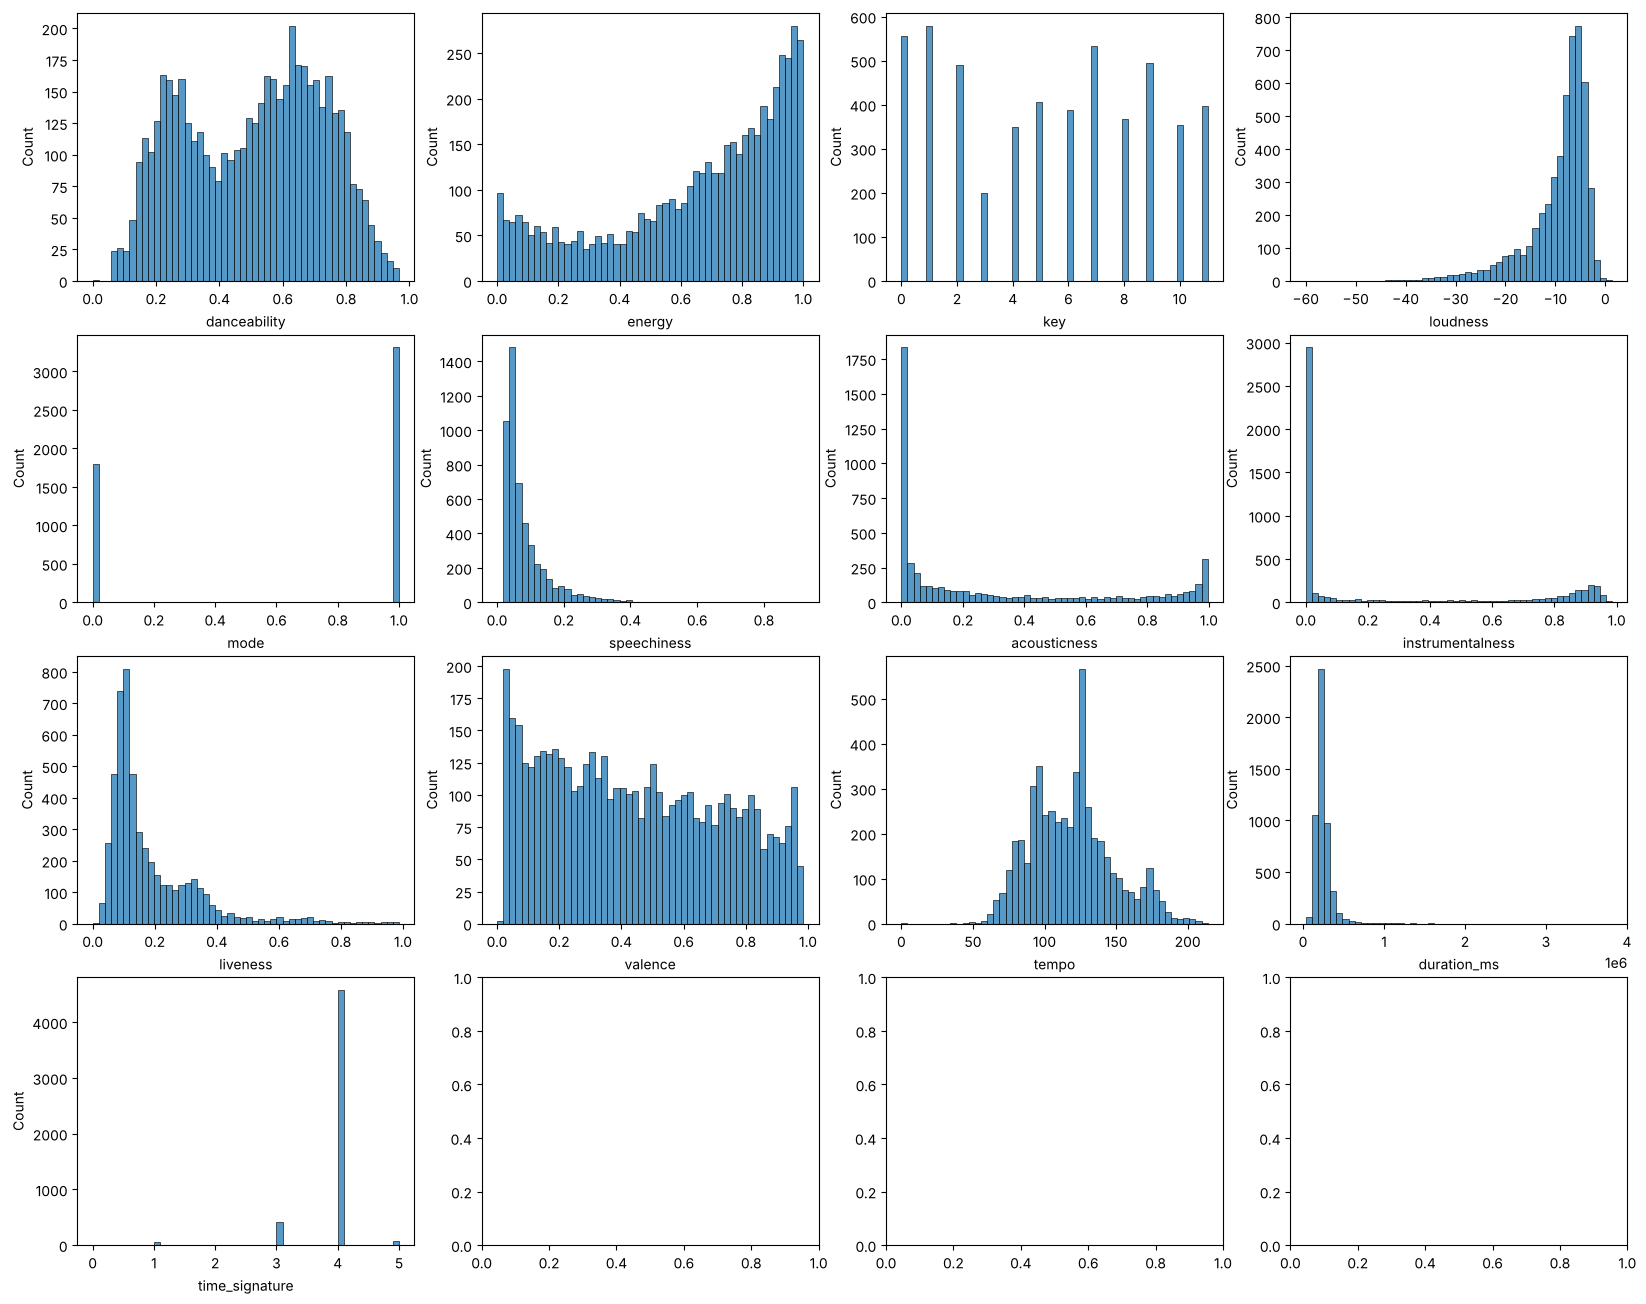

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))   # axes is a 4 x 4 grid of plots

# axes.flat reads the grid like text (left to right, top to bottom) and gives one plot per feature
for ax, col in zip(axes.flat, songs_df.columns):
    sns.histplot(songs_df[col], bins=50, ax=ax)

- **Skewed features:** `speechiness`, `liveness` and `duration_ms` have most songs at low values and a long tail to the right.
  `loudness` has a long tail to the left.
- **Two-peaked features:** `instrumentalness` and `acousticness` have many songs near 0 and another group near 1.
- **Categories, not amounts:** `key` (0–11), `mode` (0 or 1) and `time_signature` (mostly 4) only take a few whole values.

## 6. Why we need scaling: distance heatmaps

We take 25 random songs and draw the distance between every pair. Dark = similar, light = different.

In [16]:
# 25 random songs; random_state makes sure we get the same 25 every time we run the notebook
sample_df = songs_df.sample(25, random_state=42)

In [17]:
def distance_heatmap(df, ax, title):
    """Draw the distance between every pair of songs in df as a heatmap."""
    distances = pd.DataFrame(pairwise_distances(df))
    sns.heatmap(distances, ax=ax, linewidths=.2)
    ax.set_title(title)

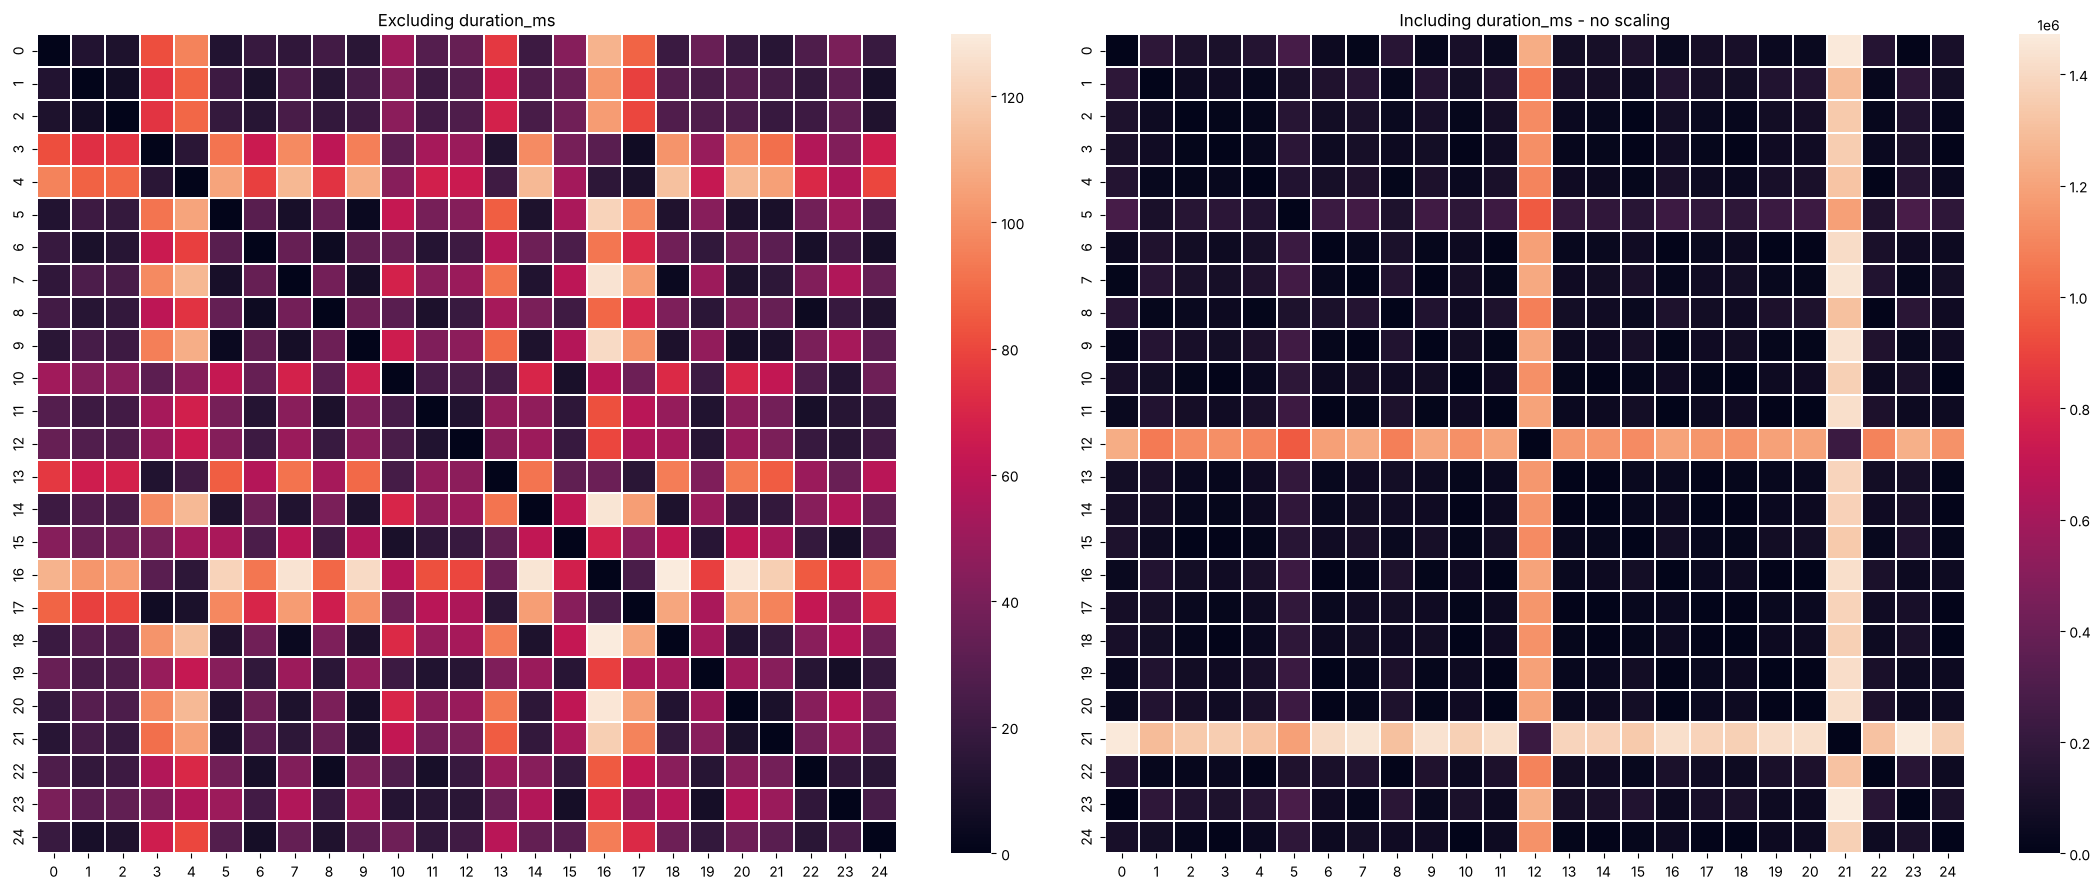

In [18]:
# Left: without duration_ms. Right: with duration_ms (and no scaling)
no_duration_df = sample_df.drop(columns='duration_ms')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(no_duration_df, ax1, 'Excluding duration_ms')
distance_heatmap(sample_df, ax2, 'Including duration_ms - no scaling')
plt.tight_layout()
plt.show()

With `duration_ms` included, the heatmap only shows which songs have a similar **length**. Everything else disappears.

### How much "say" does each feature have?
The variance of a feature measures how spread out it is, and so how much it adds to the distance between songs.
Its share of the total variance = its share of the decision.

In [19]:
variances = songs_df.var()               # how spread out each feature is
(100 * variances / variances.sum()).round(3)   # share of the total, in %

danceability          0.0
energy                0.0
key                   0.0
loudness              0.0
mode                  0.0
speechiness           0.0
acousticness          0.0
instrumentalness      0.0
liveness              0.0
valence               0.0
tempo                 0.0
duration_ms         100.0
time_signature        0.0
dtype: float64

Without scaling, `duration_ms` decides almost 100% of the distance. We need to scale.

# 7. Scaling
We try five ways to scale and compare them on the same three checks:
1. the histogram of `duration_ms` (does the shape change?),
2. the distance heatmap of our 25 songs,
3. each feature's share of the distance.

### 7.1 MinMax Scaler
Squeezes every feature into the range 0 to 1: `(value - min) / (max - min)`.

In [20]:
from sklearn.preprocessing import MinMaxScaler

In [21]:
scaler = MinMaxScaler()
songs_minmax = scaler.fit_transform(songs_df)   # learn min and max of each column, then rescale

# The scaler returns a NumPy array, so we put the song names and column names back
songs_minmax_df = pd.DataFrame(songs_minmax, index=songs_df.index, columns=songs_df.columns).round(3)

In [22]:
variances = songs_minmax_df.var()
(100 * variances / variances.sum()).round(3)

danceability         5.745
energy               9.498
key                 11.902
loudness             1.198
mode                25.771
speechiness          0.670
acousticness        14.524
instrumentalness    16.131
liveness             2.606
valence              8.980
tempo                2.023
duration_ms          0.148
time_signature       0.804
dtype: float64

Text(0.5, 1.0, 'with MinMax scaling')

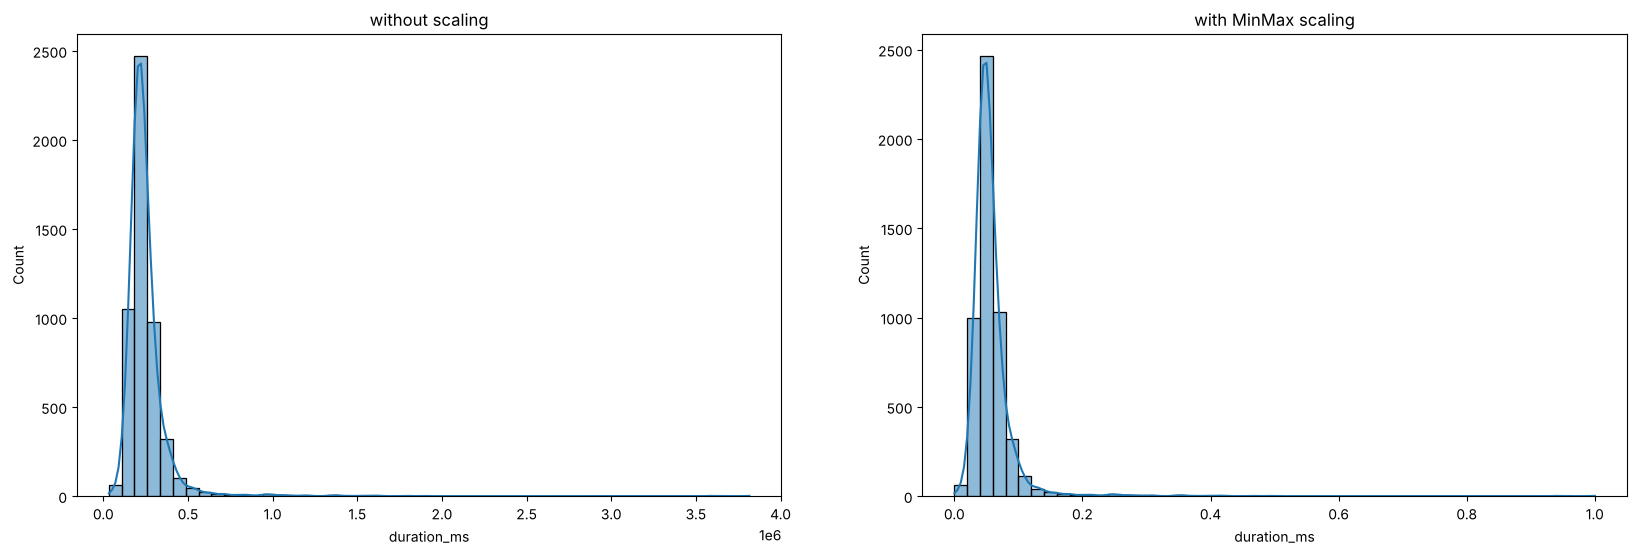

In [23]:
# Same feature before and after: the range changes, the shape stays the same
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
sns.histplot(songs_df['duration_ms'], bins=50, ax=ax1, kde=True)
sns.histplot(songs_minmax_df['duration_ms'], bins=50, ax=ax2, kde=True)
ax1.set_title('without scaling')
ax2.set_title('with MinMax scaling')

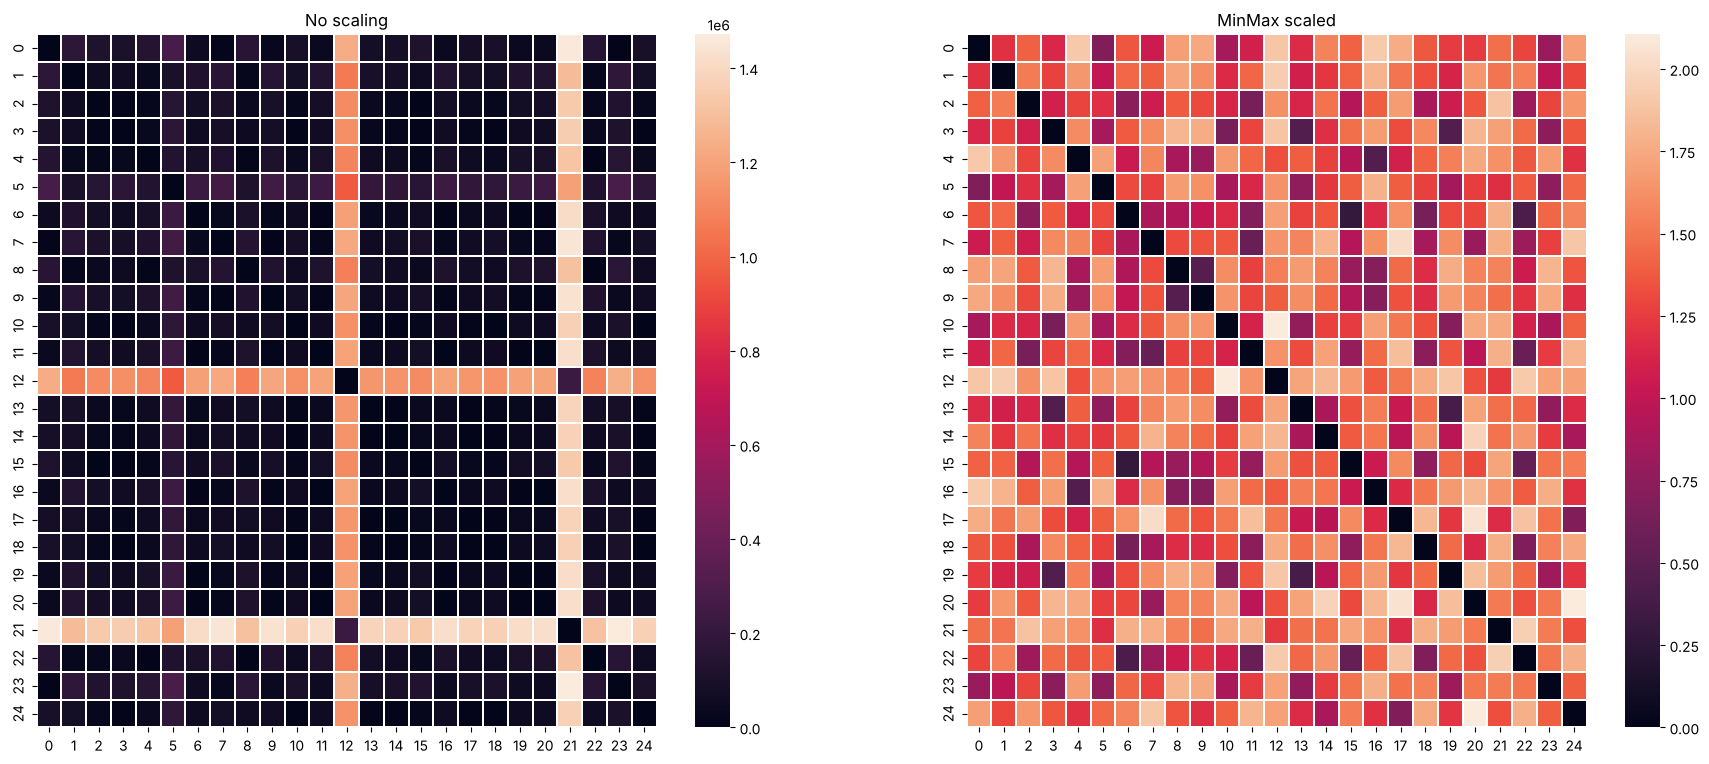

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(sample_df, ax1, 'No scaling')
distance_heatmap(songs_minmax_df.loc[sample_df.index], ax2, 'MinMax scaled')
plt.show()

### 7.2 Standard Scaler
Centres every feature on 0 and gives it a standard deviation of 1: `(value - mean) / std`.

In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
scaler = StandardScaler()
songs_standard = scaler.fit_transform(songs_df)
songs_standard_df = pd.DataFrame(songs_standard, index=songs_df.index, columns=songs_df.columns)
songs_standard_df.round(3)

,,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,artist,,,,,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.696,-1.360,1.606,-0.593,-1.357,-0.176,1.127,-0.702,5.268,-0.486,-0.288,0.056,0.234
Saudade De Bahia,Antônio Carlos Jobim,1.081,-0.877,-0.914,-0.515,0.737,-0.684,-0.209,-0.702,-0.524,0.908,0.224,-0.414,0.234
"Canta Canta, Minha Gente",Martinho Da Vila,1.581,0.265,-0.914,-0.262,0.737,3.736,0.452,-0.702,-0.411,1.671,-0.871,-0.703,0.234
Mulher Eu Sei,Chico César,0.911,-2.080,-0.354,-1.381,0.737,-0.508,1.645,-0.702,1.337,0.299,-0.413,-0.455,0.234
Rosa Morena,Kurt Elling,0.664,-1.843,0.206,-1.649,0.737,-0.636,1.749,-0.701,-0.544,-0.140,0.081,0.183,0.234
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,-1.396,-2.014,-0.634,-2.216,0.737,-0.505,1.751,1.219,-0.683,-1.352,-1.073,5.451,0.234
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,-1.460,-1.905,0.206,-1.976,0.737,-0.549,1.578,0.442,-0.775,-1.460,-1.240,4.429,0.234
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,-2.049,-2.250,1.046,-5.315,0.737,-0.560,1.847,1.902,-0.723,-1.464,-1.644,-0.076,-2.138


Text(0.5, 1.0, 'with Standard scaling')

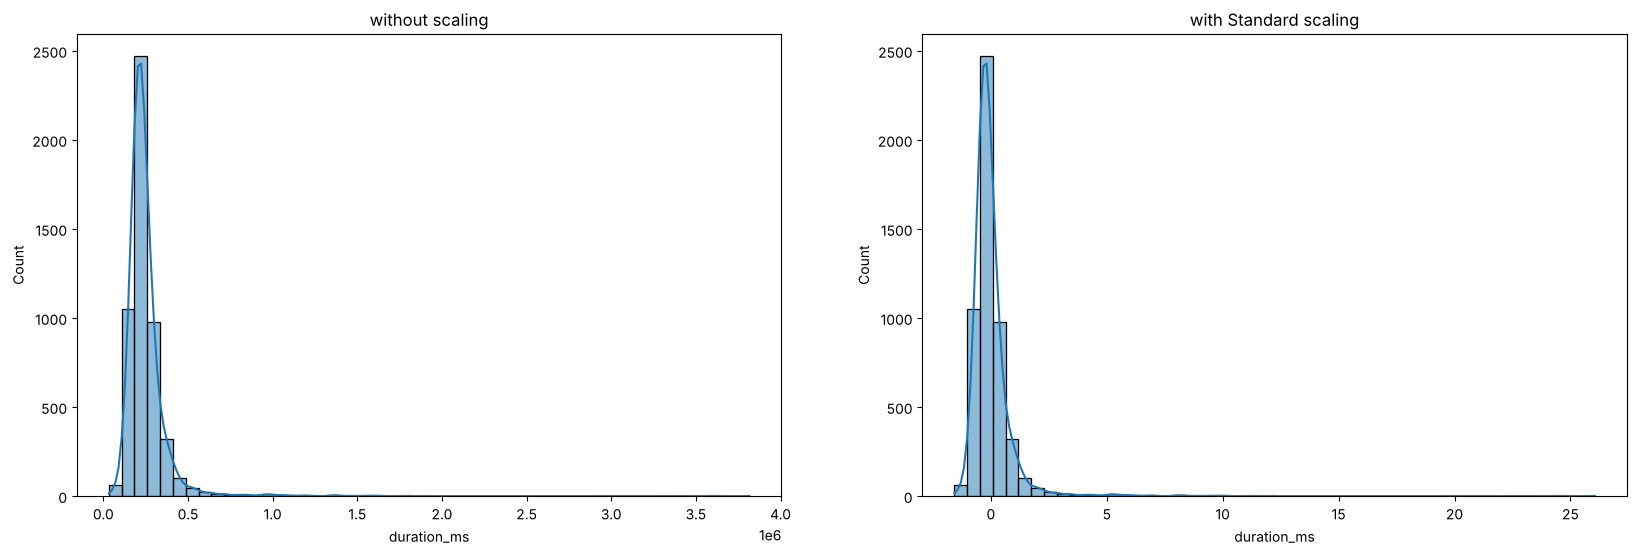

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
sns.histplot(songs_df['duration_ms'], bins=50, ax=ax1, kde=True)
sns.histplot(songs_standard_df['duration_ms'], bins=50, ax=ax2, kde=True)
ax1.set_title('without scaling')
ax2.set_title('with Standard scaling')

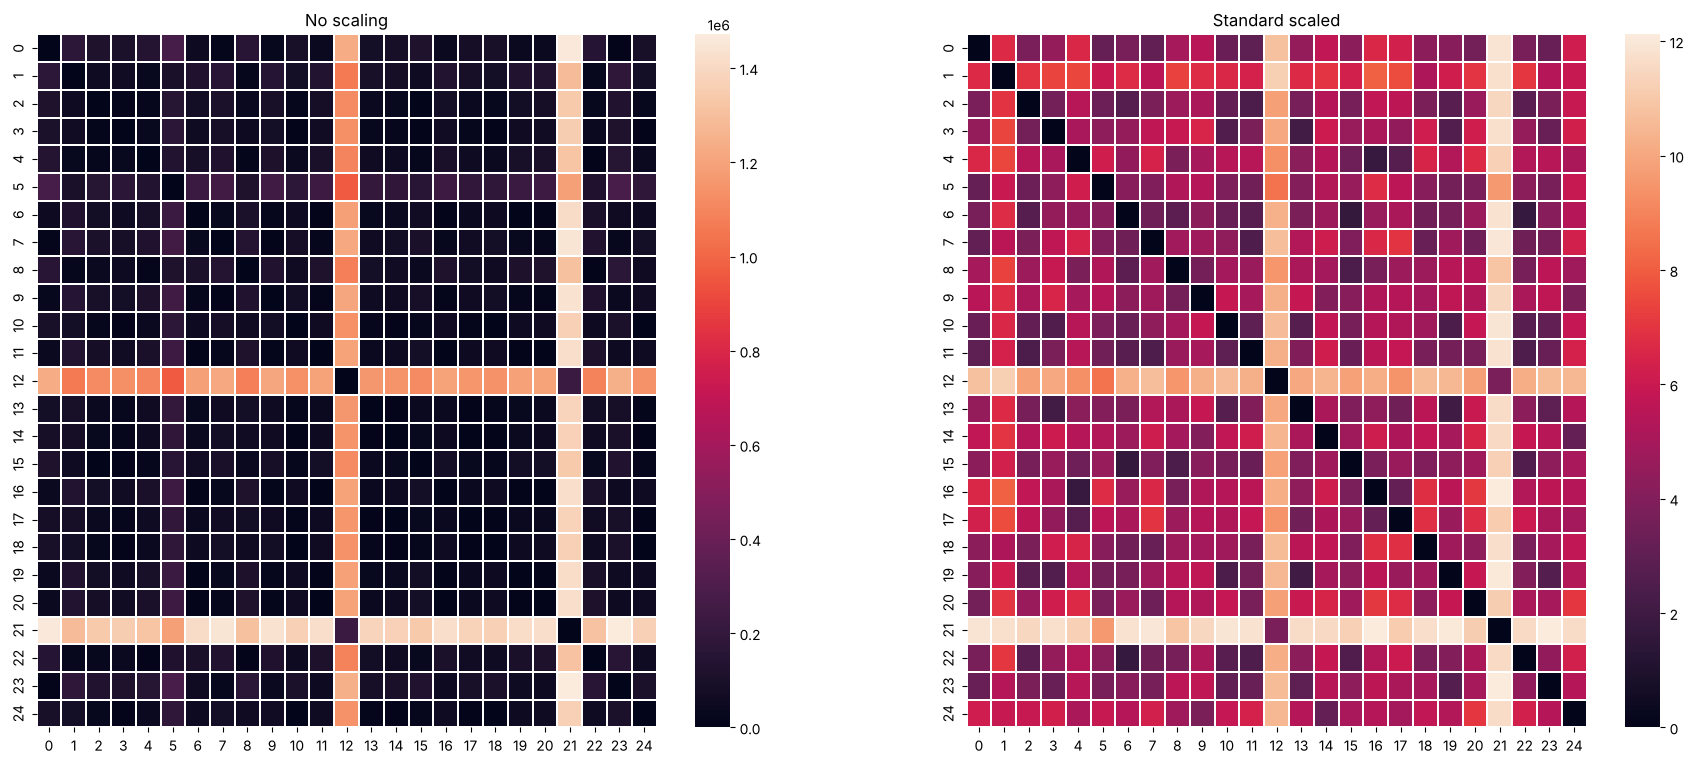

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(sample_df, ax1, 'No scaling')
distance_heatmap(songs_standard_df.loc[sample_df.index], ax2, 'Standard scaled')
plt.show()

In [29]:
variances = songs_standard_df.var()
(100 * variances / variances.sum()).round(3)

danceability        7.692
energy              7.692
key                 7.692
loudness            7.692
mode                7.692
speechiness         7.692
acousticness        7.692
instrumentalness    7.692
liveness            7.692
valence             7.692
tempo               7.692
duration_ms         7.692
time_signature      7.692
dtype: float64

Every feature gets the **same share**: StandardScaler makes every variance equal to 1.
That also means `key`, `mode` and `time_signature` get as much say as `energy`, even though they say much less about
how a song sounds. Scaling makes features *equal*, but it can't tell which features are *meaningful*. That choice is ours.

### 7.3 Robust Scaler
Like StandardScaler, but uses the median and the middle 50% of songs, so extreme songs (outliers) have less influence.

In [30]:
from sklearn.preprocessing import RobustScaler

In [31]:
scaler = RobustScaler()
songs_robust = scaler.fit_transform(songs_df)
songs_robust_df = pd.DataFrame(songs_robust, index=songs_df.index, columns=songs_df.columns)
songs_robust_df.round(3)

,,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,artist,,,,,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.326,-1.138,1.000,-0.950,-1.0,0.252,1.051,-0.003,5.882,-0.222,-0.226,0.375,0.0
Saudade De Bahia,Antônio Carlos Jobim,0.547,-0.805,-0.500,-0.869,0.0,-0.347,0.212,-0.004,-0.125,0.585,0.159,-0.405,0.0
"Canta Canta, Minha Gente",Martinho Da Vila,0.834,-0.019,-0.500,-0.605,0.0,4.868,0.627,-0.003,-0.007,1.027,-0.665,-0.885,0.0
Mulher Eu Sei,Chico César,0.450,-1.634,-0.167,-1.769,0.0,-0.139,1.377,-0.004,1.806,0.232,-0.320,-0.474,0.0
Rosa Morena,Kurt Elling,0.308,-1.470,0.167,-2.048,0.0,-0.290,1.442,-0.003,-0.145,-0.022,0.051,0.587,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,-0.874,-1.588,-0.333,-2.638,0.0,-0.135,1.443,1.080,-0.289,-0.723,-0.817,9.335,0.0
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,-0.911,-1.513,0.167,-2.388,0.0,-0.187,1.334,0.642,-0.385,-0.786,-0.943,7.637,0.0
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,-1.248,-1.751,0.667,-5.861,0.0,-0.200,1.503,1.465,-0.331,-0.788,-1.246,0.157,-1.0


Text(0.5, 1.0, 'with Robust scaling')

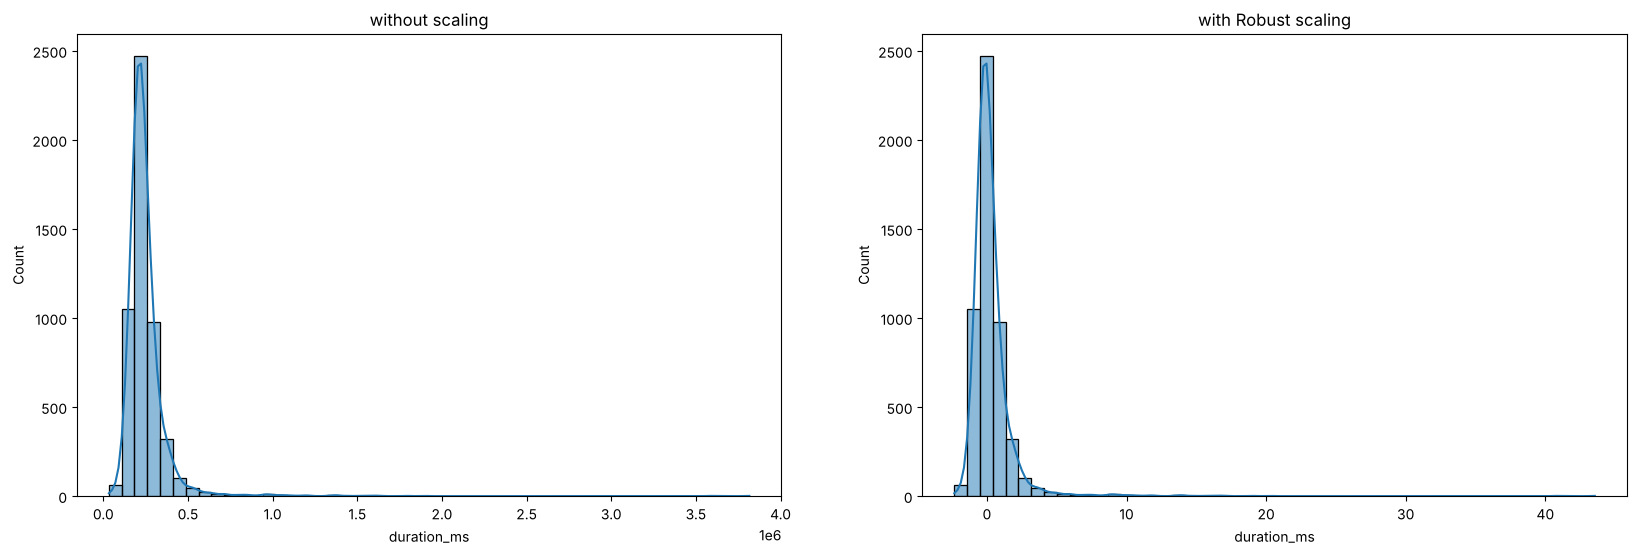

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
sns.histplot(songs_df['duration_ms'], bins=50, ax=ax1, kde=True)
sns.histplot(songs_robust_df['duration_ms'], bins=50, ax=ax2, kde=True)
ax1.set_title('without scaling')
ax2.set_title('with Robust scaling')

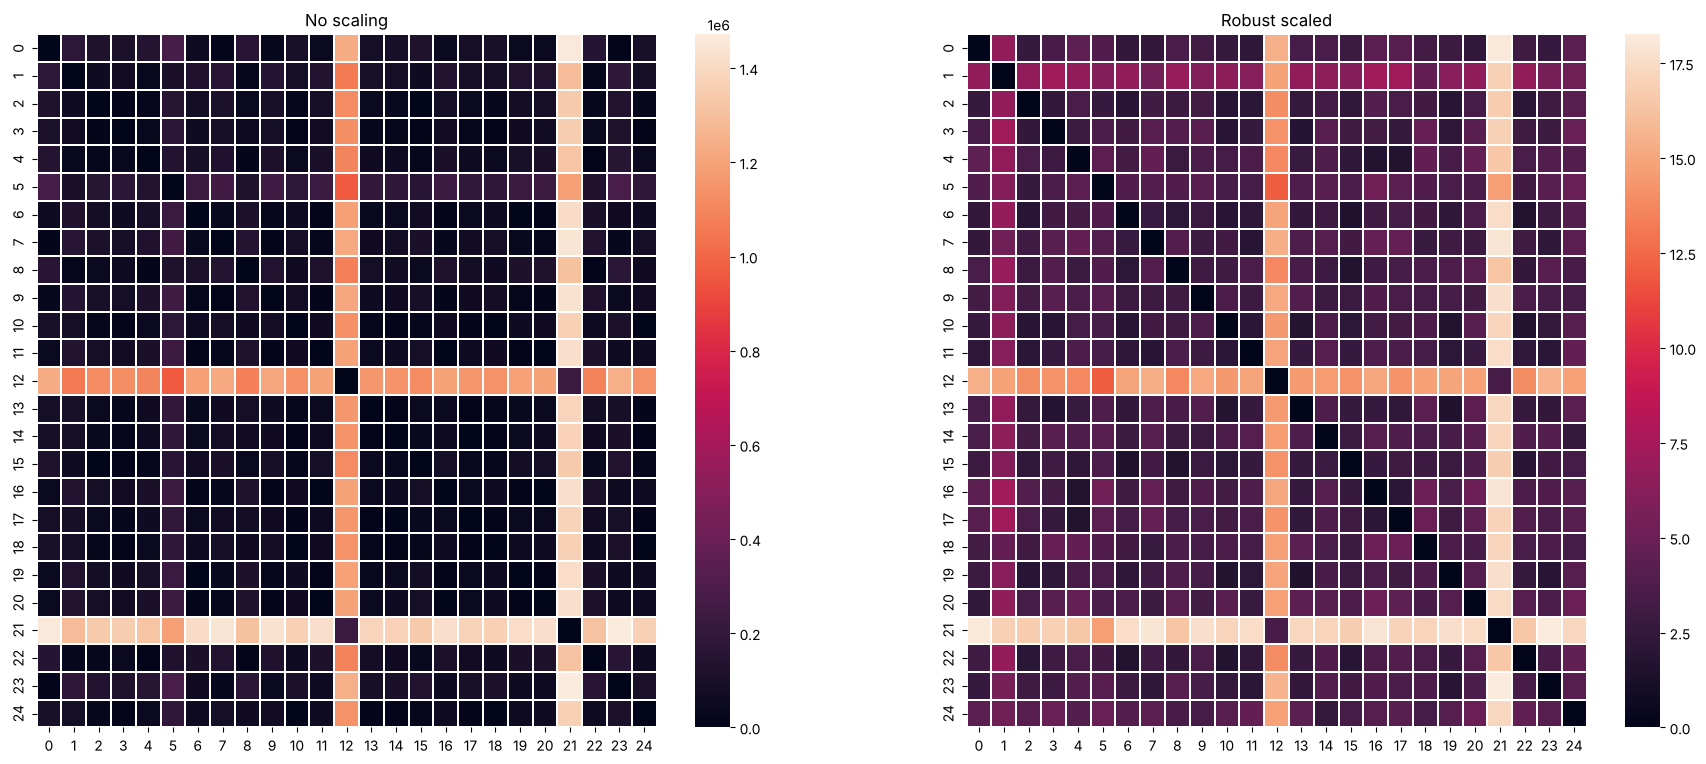

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(sample_df, ax1, 'No scaling')
distance_heatmap(songs_robust_df.loc[sample_df.index], ax2, 'Robust scaled')
plt.show()

In [34]:
variances = songs_robust_df.var()
(100 * variances / variances.sum()).round(3)

danceability         3.471
energy               4.999
key                  3.735
loudness            11.406
mode                 2.404
speechiness         14.679
acousticness         4.158
instrumentalness     3.355
liveness            11.341
valence              3.532
tempo                5.973
duration_ms         29.074
time_signature       1.874
dtype: float64

## 8. Transformers: changing the range *and* the shape
Scalers only change the range. Transformers also reshape the distribution, which pulls in long tails.

### 8.1 Quantile Transformer
Ranks the songs and spreads them evenly between 0 and 1. Every histogram becomes flat.

In [35]:
from sklearn.preprocessing import QuantileTransformer

In [36]:
scaler = QuantileTransformer()
songs_quantile = scaler.fit_transform(songs_df)
songs_quantile_df = pd.DataFrame(songs_quantile, index=songs_df.index, columns=songs_df.columns)
songs_quantile_df

,,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,artist,,,,,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.706206,0.147823,1.000000,0.189209,0.0,0.615616,0.789289,0.378421,0.998999,0.381381,0.412314,0.681682,0.539039
Saudade De Bahia,Antônio Carlos Jobim,0.837337,0.209209,0.269770,0.206307,1.0,0.157157,0.607840,0.261717,0.369870,0.766767,0.594595,0.261206,0.539039
"Canta Canta, Minha Gente",Martinho Da Vila,0.963964,0.489990,0.269770,0.263794,1.0,0.987716,0.714715,0.381568,0.492993,0.941942,0.198625,0.078215,0.539039
Mulher Eu Sei,Chico César,0.783784,0.038684,0.390891,0.098169,1.0,0.401902,0.863363,0.366615,0.919311,0.614615,0.373910,0.230770,0.539039
Rosa Morena,Kurt Elling,0.694194,0.081207,0.542543,0.076524,1.0,0.231732,0.881882,0.436546,0.343844,0.490490,0.532179,0.755526,0.539039
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,0.095596,0.051286,0.337337,0.044578,1.0,0.405906,0.882382,0.764716,0.180180,0.079659,0.138445,0.994846,0.539039
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,0.078078,0.072072,0.542543,0.055826,1.0,0.352352,0.849459,0.705972,0.106106,0.015015,0.107123,0.992157,0.539039
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,0.000947,0.000934,0.805305,0.000953,1.0,0.338338,0.909910,0.998071,0.147448,0.010010,0.025391,0.586730,0.051051


Text(0.5, 1.0, 'with Quantile transforming')

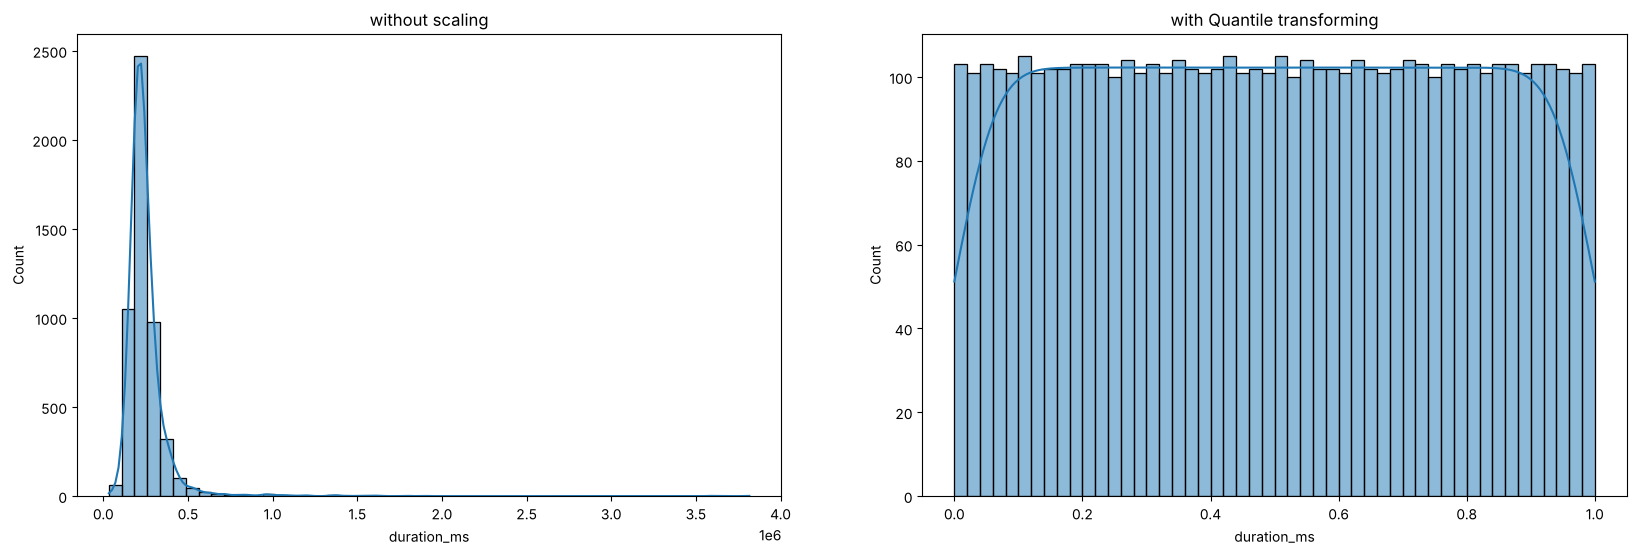

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
sns.histplot(songs_df['duration_ms'], bins=50, ax=ax1, kde=True)
sns.histplot(songs_quantile_df['duration_ms'], bins=50, ax=ax2, kde=True)
ax1.set_title('without scaling')
ax2.set_title('with Quantile transforming')

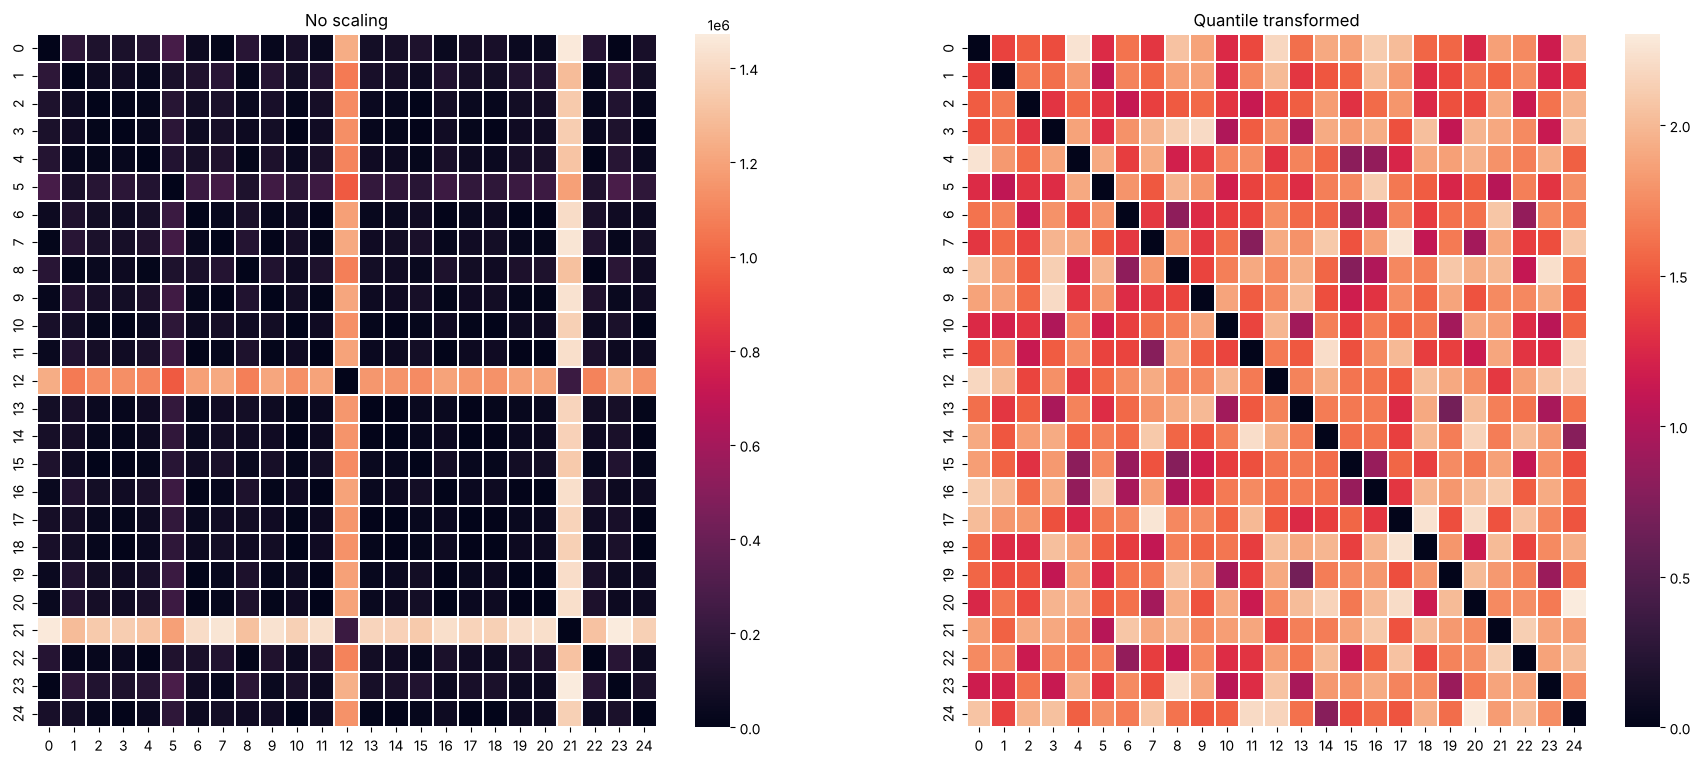

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(sample_df, ax1, 'No scaling')
distance_heatmap(songs_quantile_df.loc[sample_df.index], ax2, 'Quantile transformed')
plt.show()

In [39]:
variances = songs_quantile_df.var()
(100 * variances / variances.sum()).round(3)

danceability         6.944
energy               6.945
key                  7.597
loudness             6.945
mode                18.997
speechiness          6.945
acousticness         6.946
instrumentalness     8.936
liveness             6.945
valence              6.945
tempo                6.945
duration_ms          6.945
time_signature       1.964
dtype: float64

### 8.2 Power Transformer
Makes every feature look more like a bell curve (normal distribution) and then standardises it.
Long tails are pulled in, so a few extreme songs can't stretch the distances.

In [40]:
from sklearn.preprocessing import PowerTransformer

In [41]:
scaling = PowerTransformer()
songs_power = scaling.fit_transform(songs_df)
songs_power_df = pd.DataFrame(songs_power, index=songs_df.index, columns=songs_df.columns)
songs_power_df

,,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,artist,,,,,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.688719,-1.360619,1.450668,-0.860997,-1.357457,0.206121,1.277344,-0.781827,2.075993,-0.409539,-0.231631,0.352740,0.166414
Saudade De Bahia,Antônio Carlos Jobim,1.086162,-1.032613,-0.853262,-0.794909,0.736671,-1.040418,0.233740,-0.782357,-0.504439,0.931231,0.282697,-0.498969,0.166414
"Canta Canta, Minha Gente",Martinho Da Vila,1.608544,0.100033,-0.853262,-0.563107,0.736671,1.975996,0.907226,-0.781783,-0.255899,1.536433,-0.861321,-1.238400,0.166414
Mulher Eu Sei,Chico César,0.910536,-1.715715,-0.234975,-1.415977,0.736671,-0.526006,1.452530,-0.781997,1.522385,0.389516,-0.362226,-0.591377,0.166414
Rosa Morena,Kurt Elling,0.655806,-1.614723,0.301482,-1.570863,0.736671,-0.890399,1.480292,-0.779176,-0.551328,-0.041810,0.142220,0.536234,0.166414
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,-1.382321,-1.689002,-0.530693,-1.859491,0.736671,-0.518563,1.481015,1.397929,-0.904172,-1.470116,-1.093293,3.450837,0.166414
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,-1.443355,-1.642575,0.301482,-1.743074,0.736671,-0.636568,1.433402,1.061936,-1.167794,-1.619589,-1.290358,3.167142,0.166414
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,-1.995135,-1.779302,1.015660,-2.912583,0.736671,-0.667956,1.504773,1.535231,-1.015691,-1.625155,-1.793219,0.145227,-2.309729


Text(0.5, 1.0, 'with Power transforming')

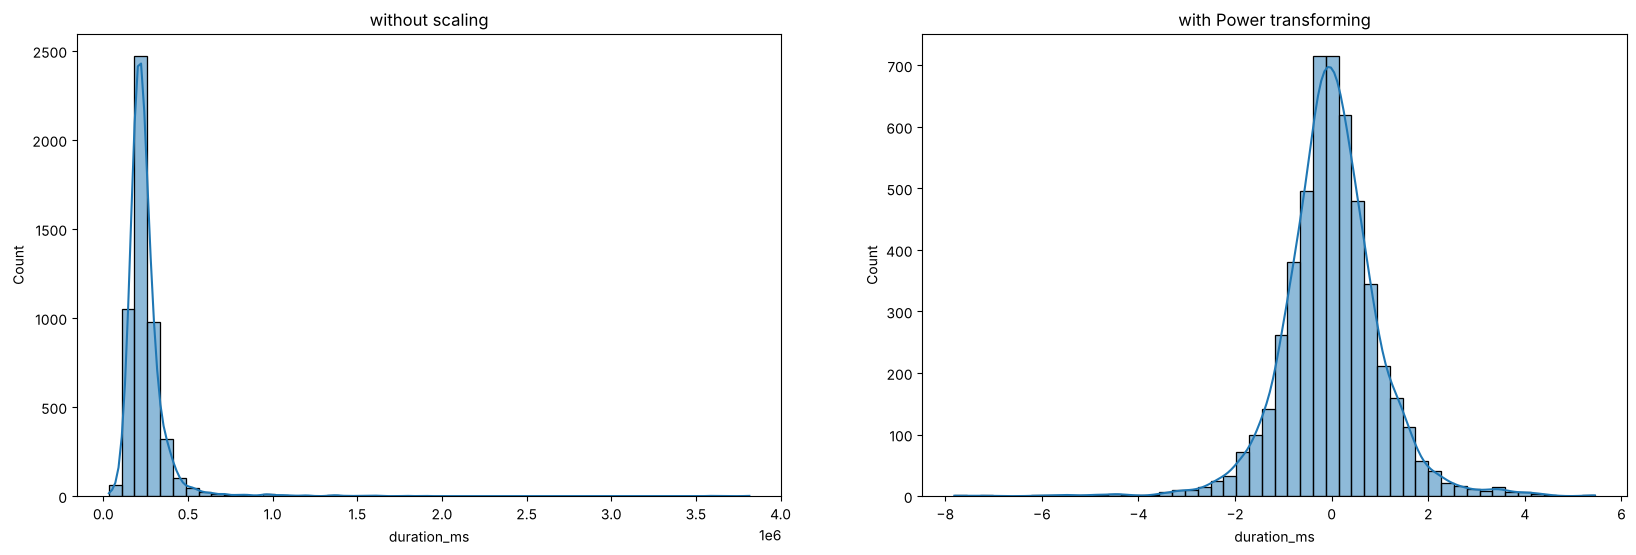

In [42]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
sns.histplot(songs_df['duration_ms'], bins=50, ax=ax1, kde=True)
sns.histplot(songs_power_df['duration_ms'], bins=50, ax=ax2, kde=True)
ax1.set_title('without scaling')
ax2.set_title('with Power transforming')

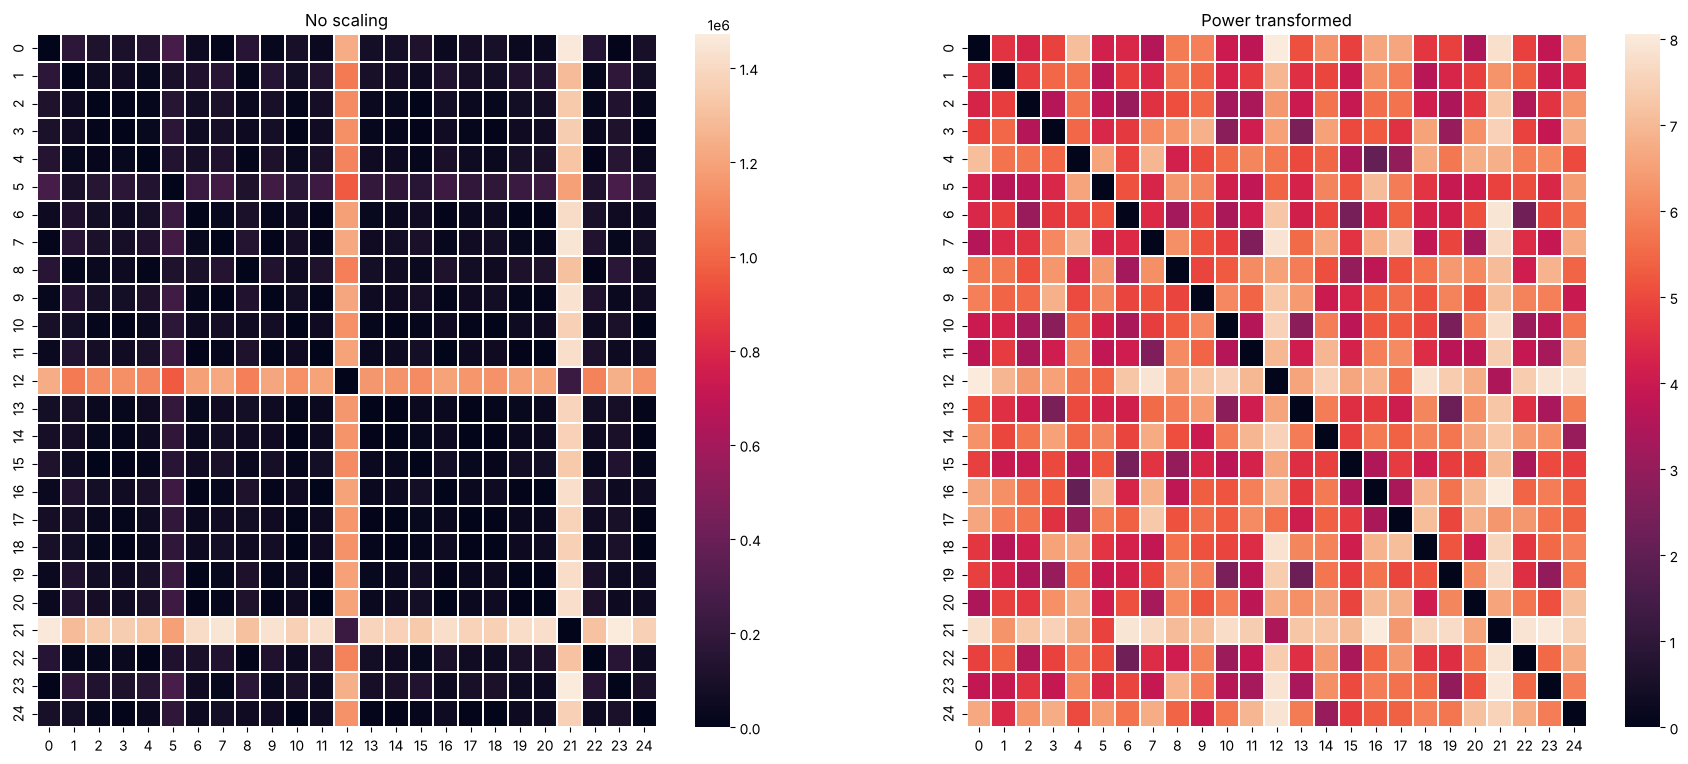

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
distance_heatmap(sample_df, ax1, 'No scaling')
distance_heatmap(songs_power_df.loc[sample_df.index], ax2, 'Power transformed')
plt.show()

In [44]:
variances = songs_power_df.var()
(100 * variances / variances.sum()).round(3)

danceability        7.692
energy              7.692
key                 7.692
loudness            7.692
mode                7.692
speechiness         7.692
acousticness        7.692
instrumentalness    7.692
liveness            7.692
valence             7.692
tempo               7.692
duration_ms         7.692
time_signature      7.692
dtype: float64

## 9. Compare all scalers side by side

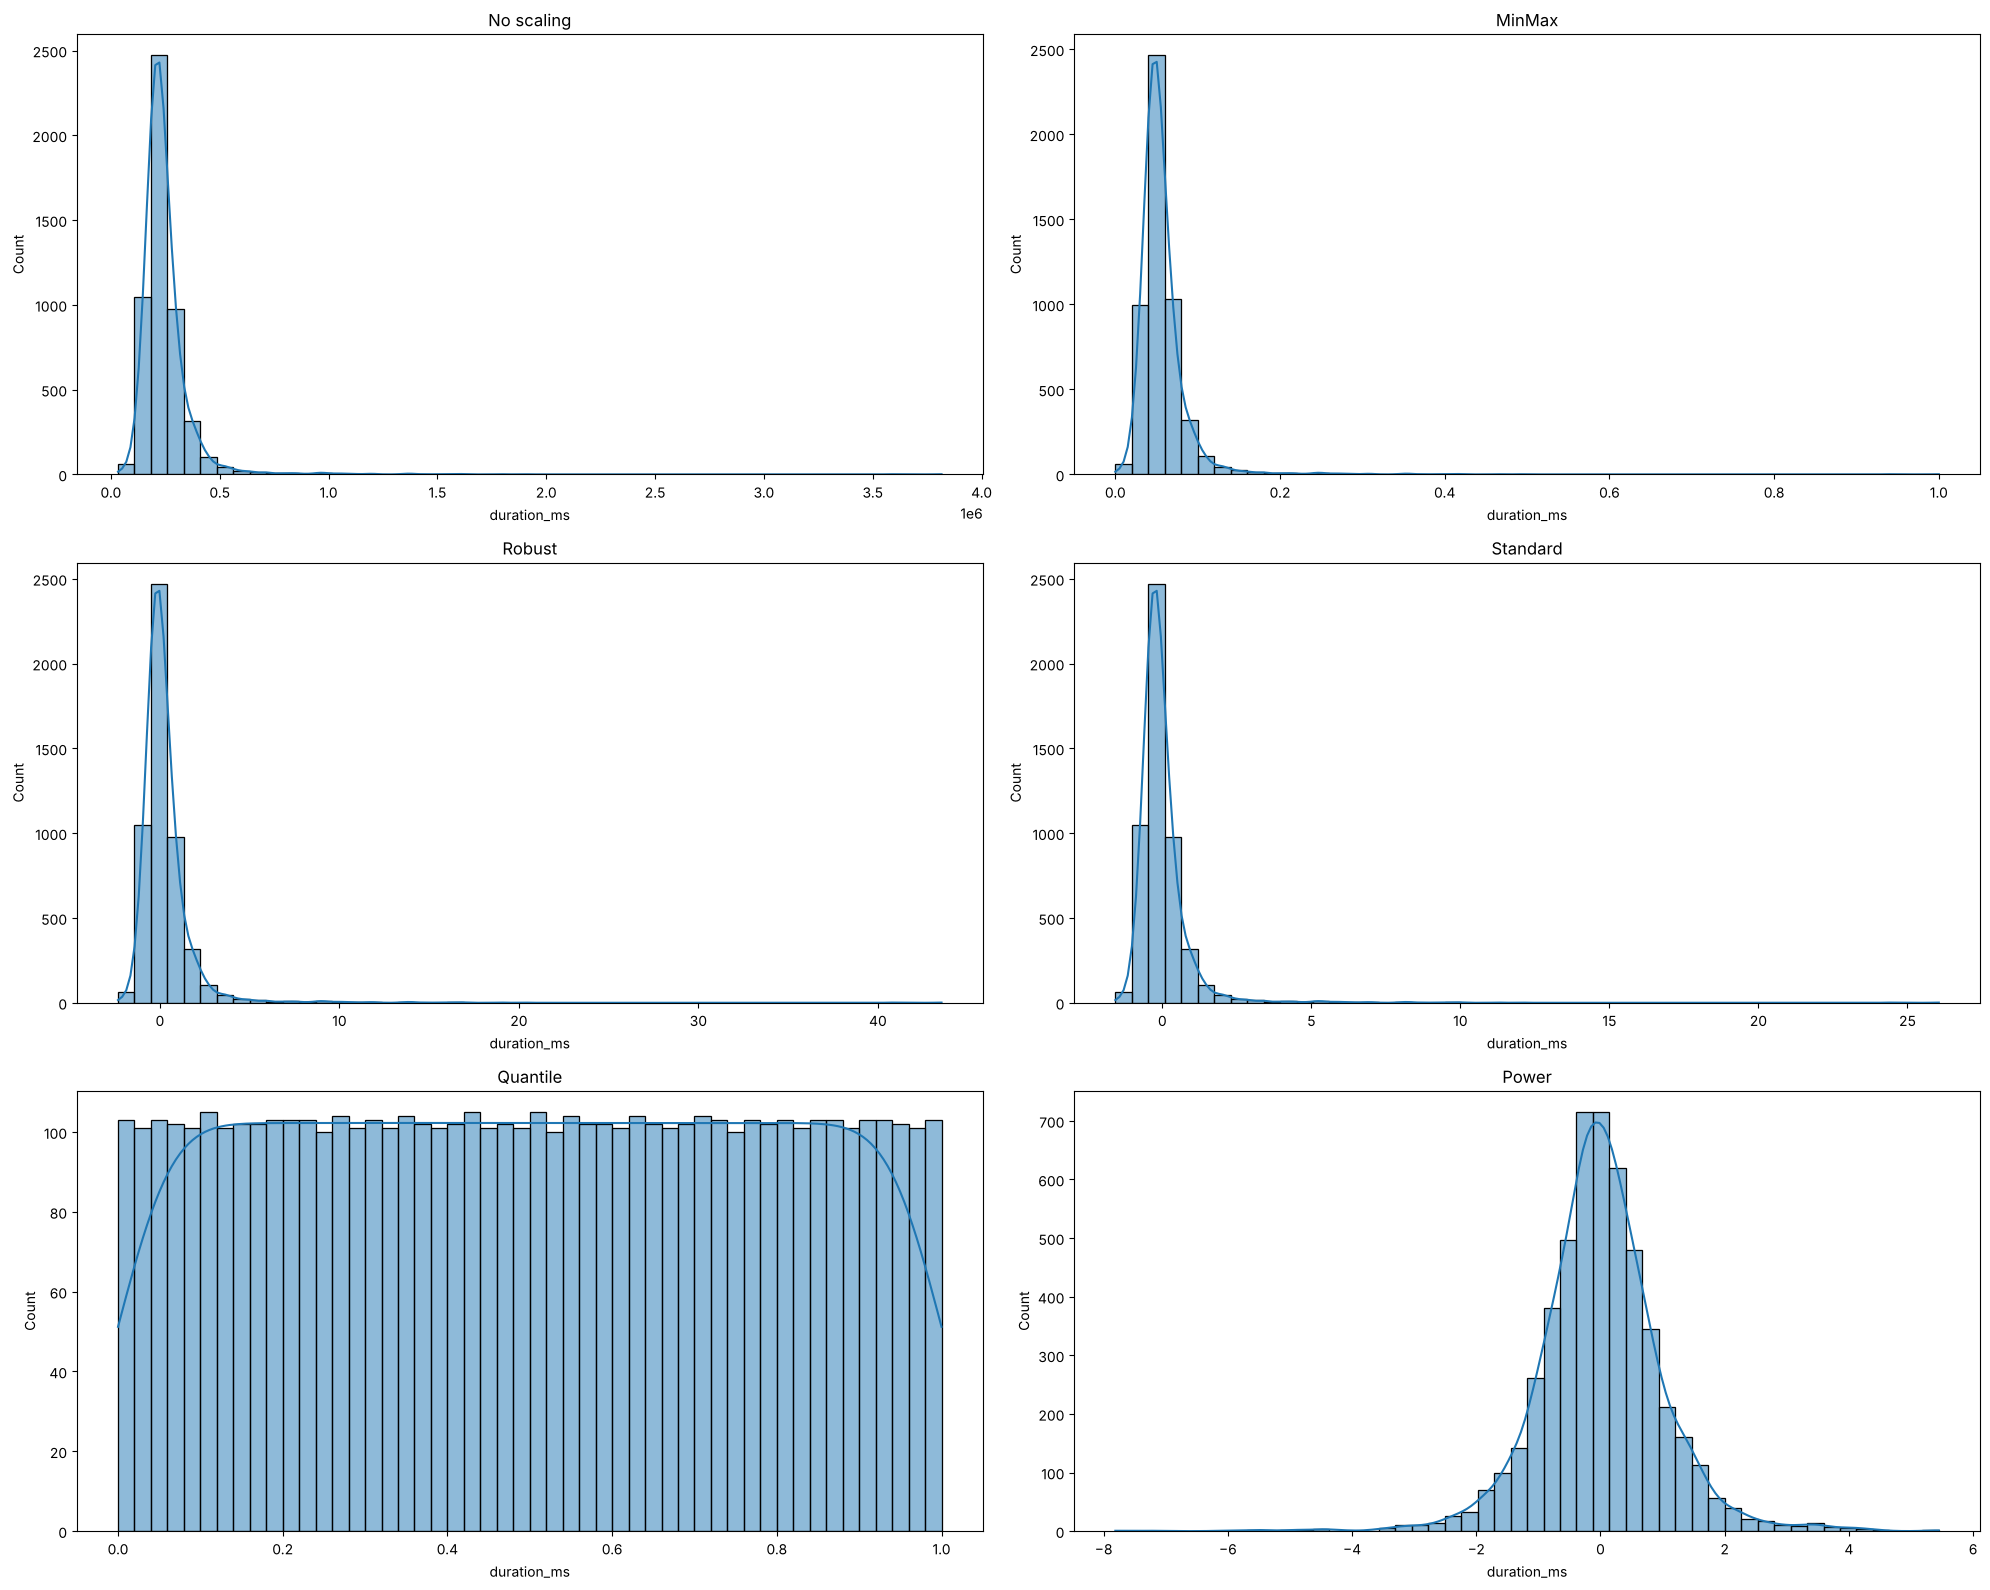

In [45]:
# All versions of the data in one dictionary, so we can loop over them
options = {
    'No scaling': songs_df,
    'MinMax': songs_minmax_df,
    'Robust': songs_robust_df,
    'Standard': songs_standard_df,
    'Quantile': songs_quantile_df,
    'Power': songs_power_df,
}

def compare_histograms(feature):
    """Show the histogram of one feature for every scaler (3 x 2 grid)."""
    fig, ax = plt.subplots(3, 2, figsize=(20, 16))
    for axis, (name, df) in zip(ax.flat, options.items()):
        sns.histplot(df[feature], bins=50, kde=True, ax=axis)
        axis.set_title(name)
    plt.tight_layout()
    plt.show()

compare_histograms('duration_ms')

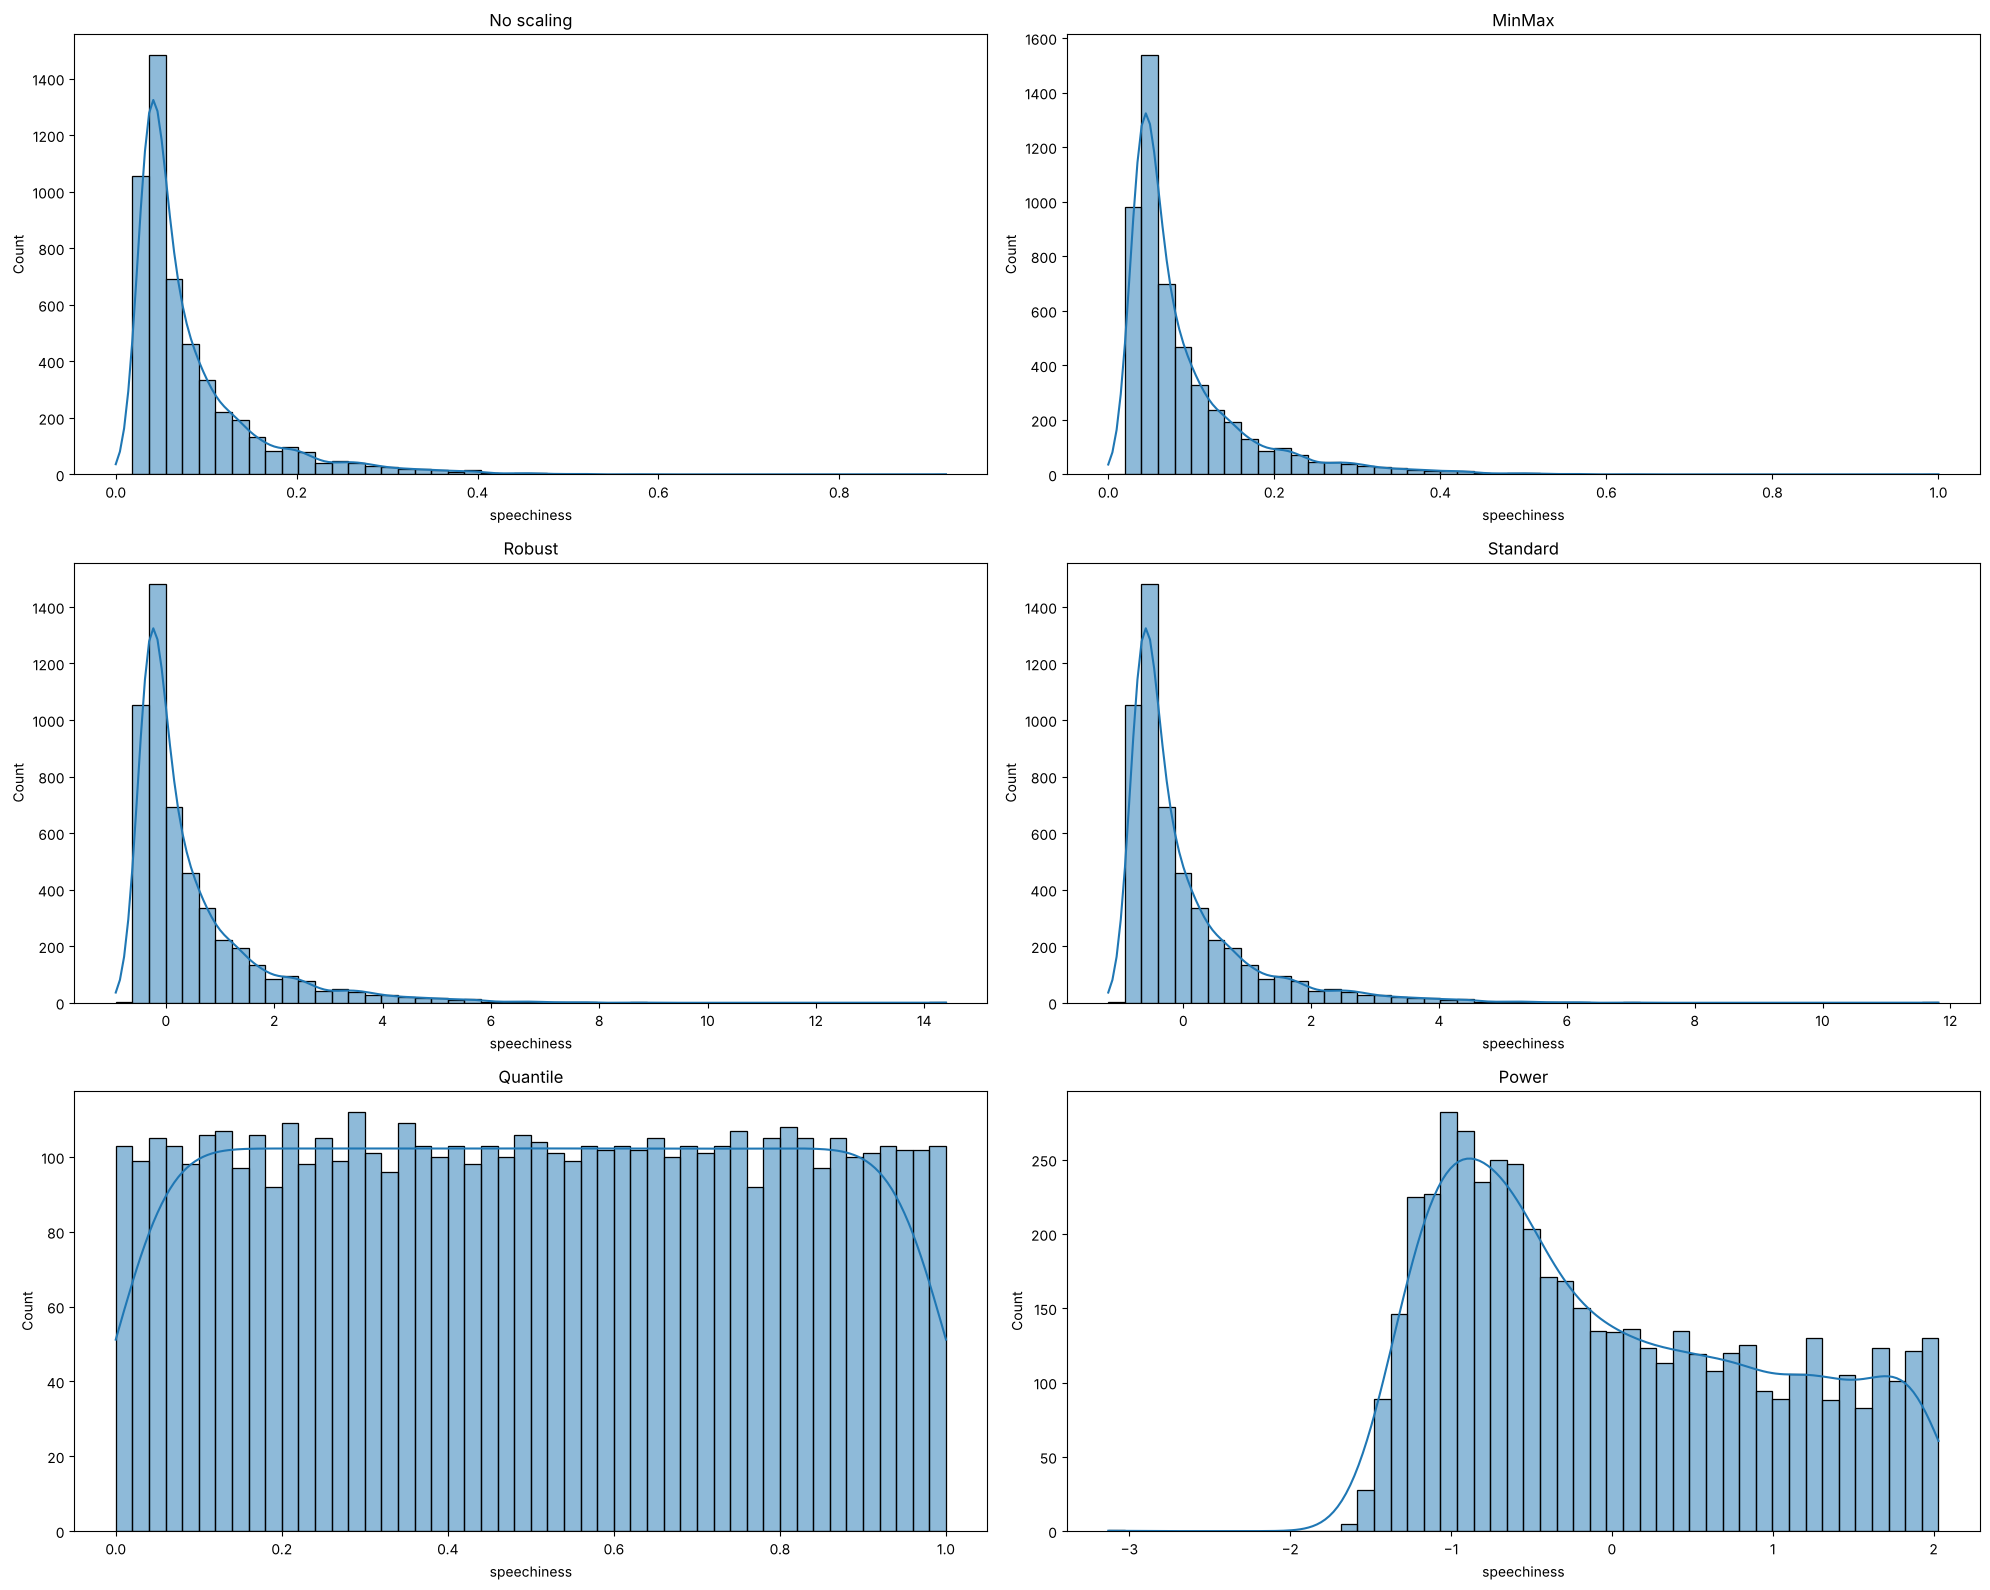

In [46]:
# speechiness has a long tail: see how each scaler handles it
compare_histograms('speechiness')

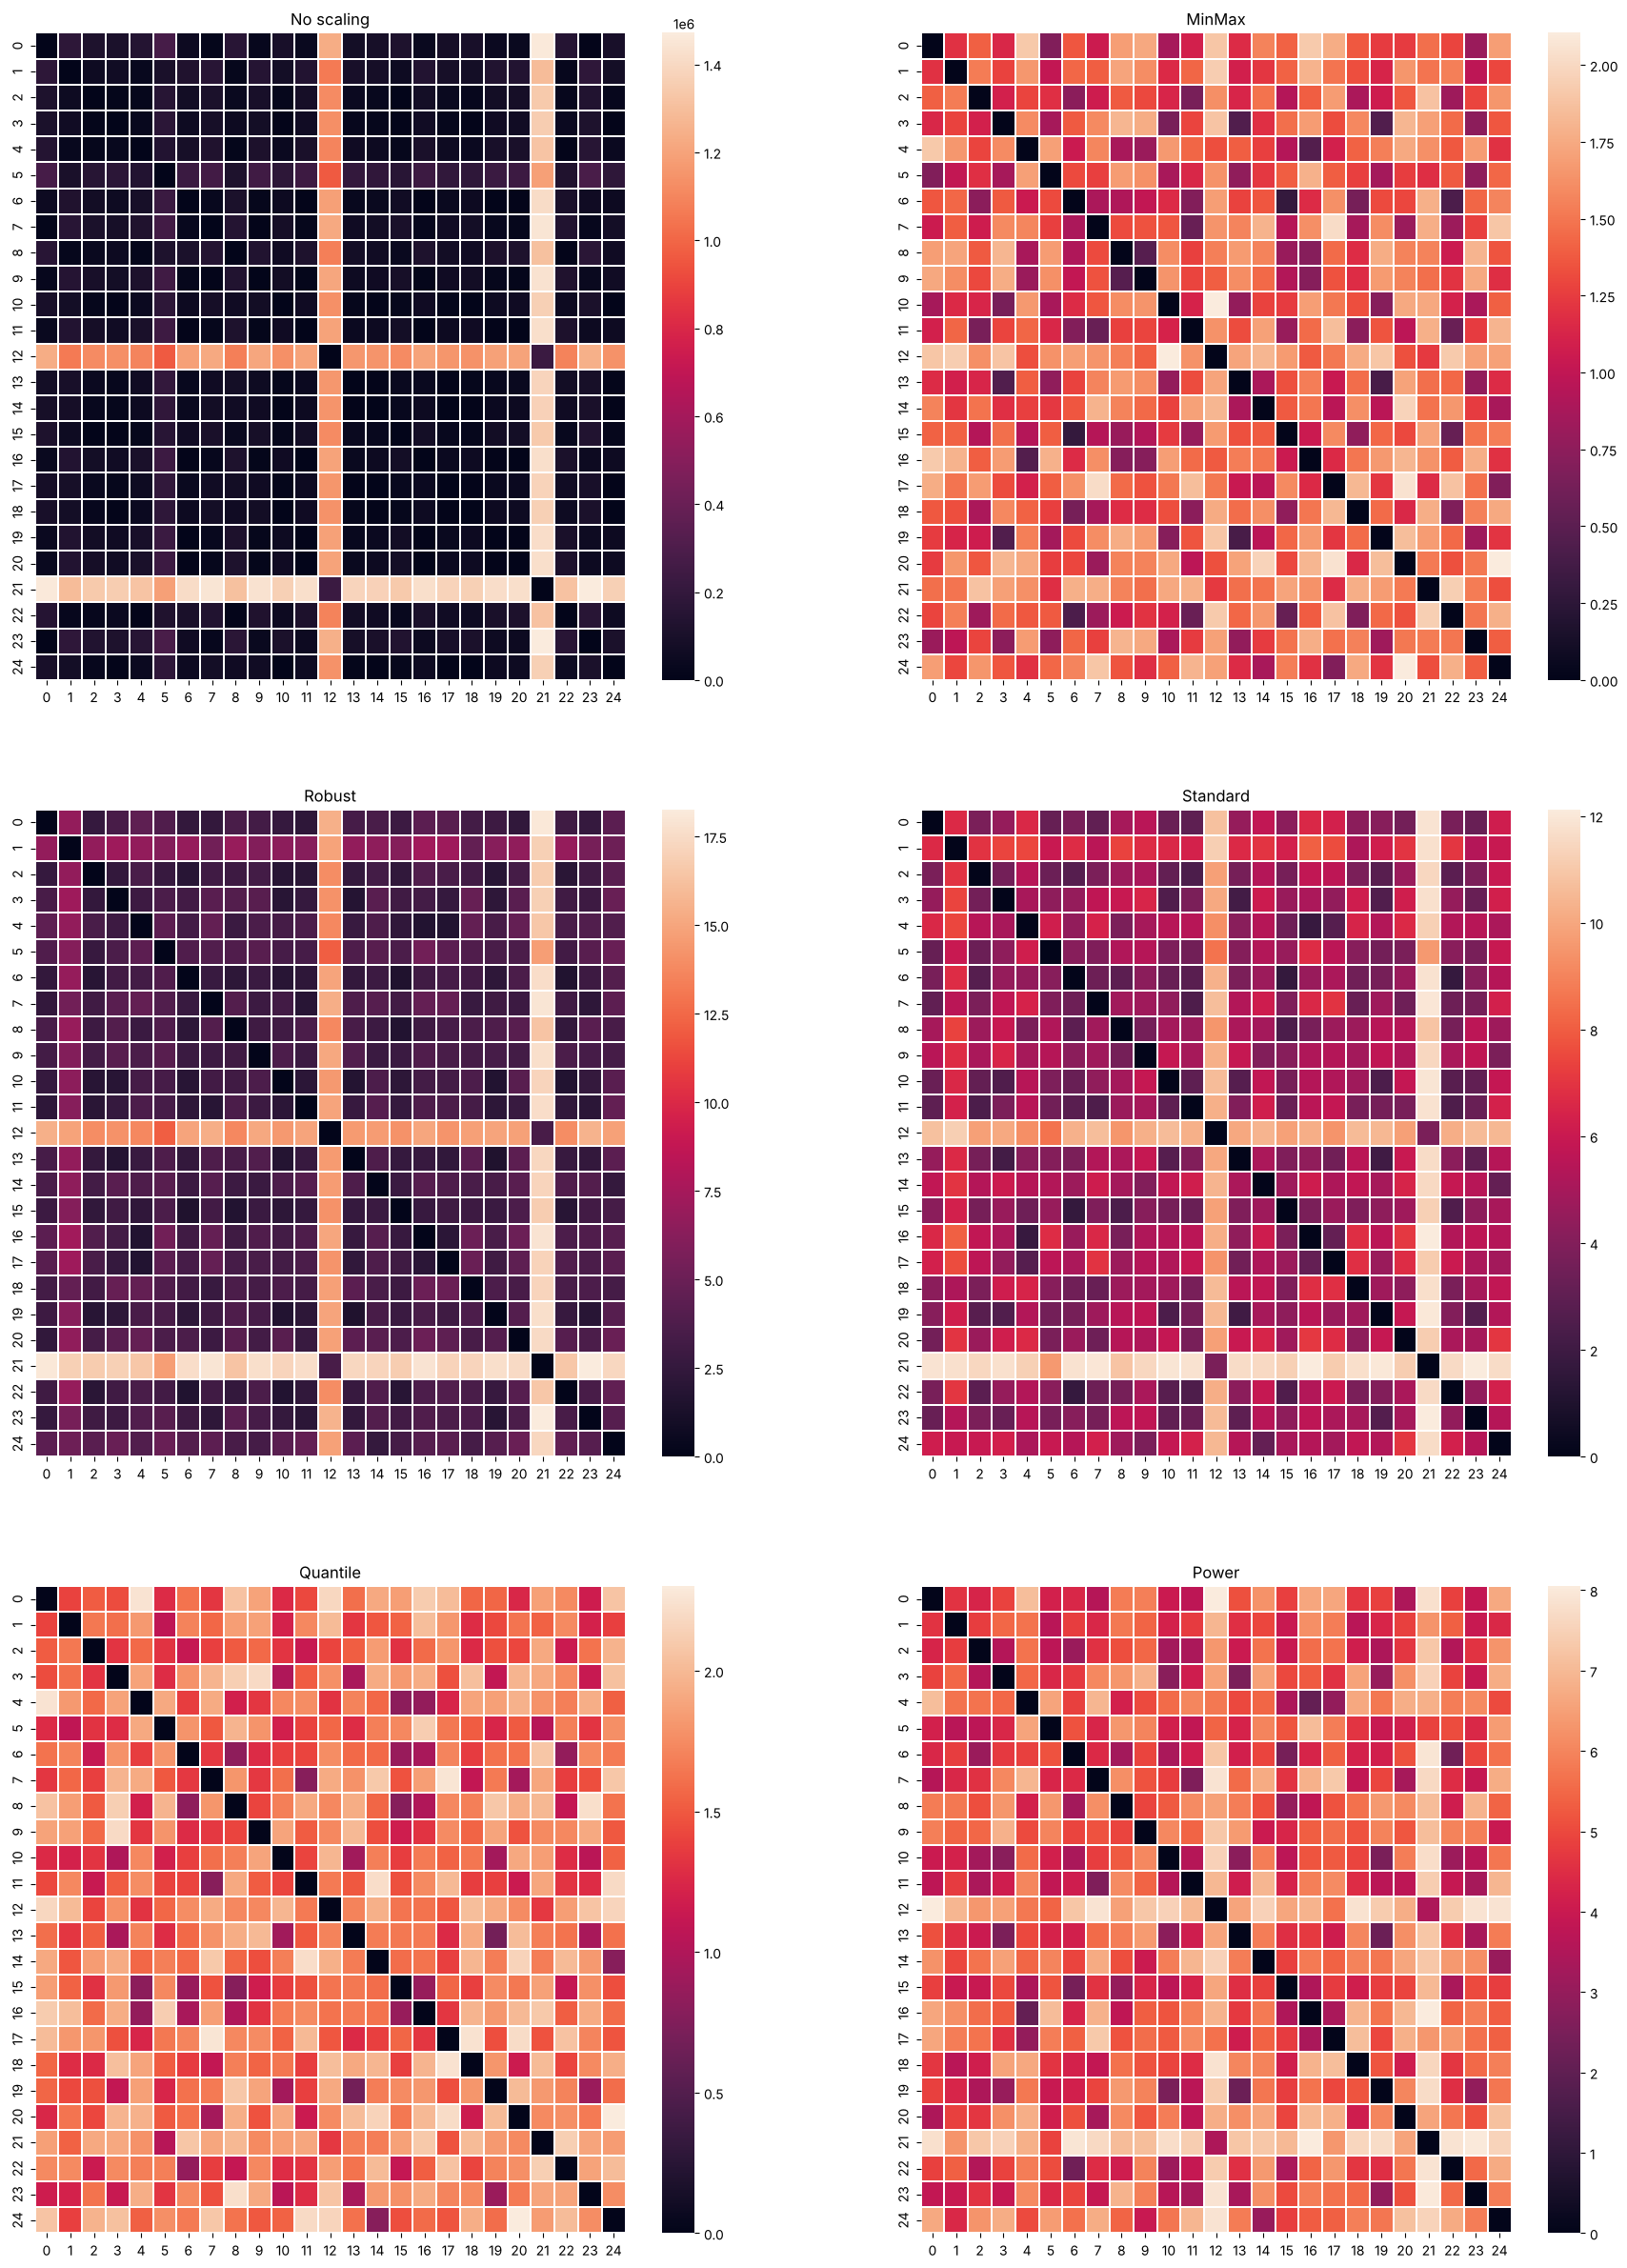

In [47]:
# Distance heatmaps of the same 25 songs, for every scaler
fig, ax = plt.subplots(3, 2, figsize=(22, 30))
for axis, (name, df) in zip(ax.flat, options.items()):
    distance_heatmap(df.loc[sample_df.index], axis, name)
plt.show()

In [48]:
def distance_share(df):
    """Each feature's share (%) of the total variance = its share of the distance between songs."""
    variances = df.var()
    return (100 * variances / variances.sum()).round(3)

# One column per scaler, one row per feature
share_table = pd.DataFrame({name: distance_share(df) for name, df in options.items()})
share_table.round(1)

,No scaling,MinMax,Robust,Standard,Quantile,Power
danceability,0.0,5.7,3.5,7.7,6.9,7.7
energy,0.0,9.5,5.0,7.7,6.9,7.7
key,0.0,11.9,3.7,7.7,7.6,7.7
loudness,0.0,1.2,11.4,7.7,6.9,7.7
mode,0.0,25.8,2.4,7.7,19.0,7.7
speechiness,0.0,0.7,14.7,7.7,6.9,7.7
acousticness,0.0,14.5,4.2,7.7,6.9,7.7
instrumentalness,0.0,16.1,3.4,7.7,8.9,7.7
liveness,0.0,2.6,11.3,7.7,6.9,7.7
valence,0.0,9.0,3.5,7.7,6.9,7.7


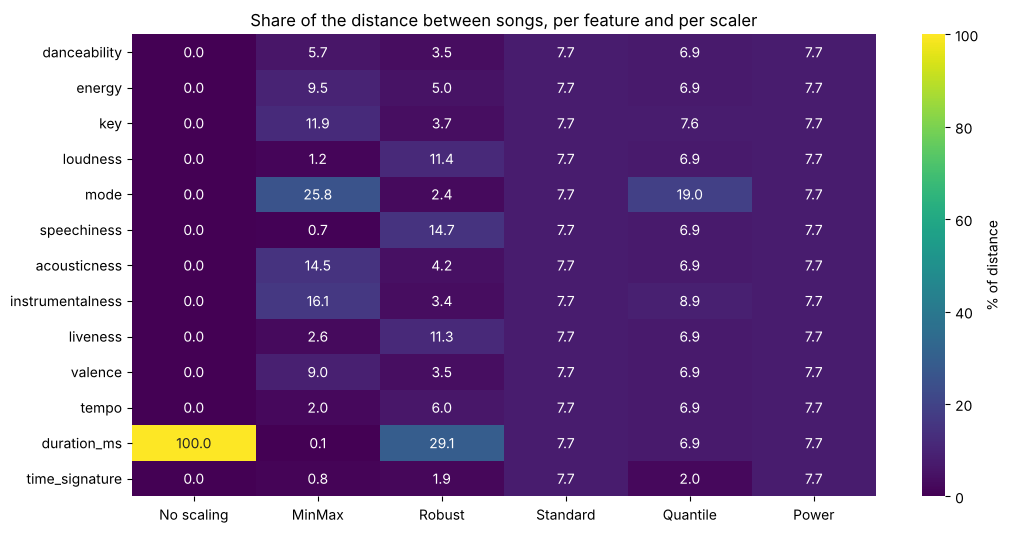

In [49]:
plt.figure(figsize=(12, 6))
sns.heatmap(share_table, annot=True, fmt='.1f', cmap='viridis', cbar_kws={'label': '% of distance'})
plt.title('Share of the distance between songs, per feature and per scaler')
plt.show()

## 10. Conclusion
- **No scaling:** `duration_ms` decides everything. Useless for playlists.
- **MinMax / Robust:** better, but features with long tails or outliers still get too little or too much say.
- **Standard / Power:** every feature gets an equal say. **PowerTransformer** also pulls in long tails.
- Scaling can't decide which features are *meaningful*. In notebook 02 we keep only the 9 audio features and drop
  `key`, `mode`, `time_signature` and `duration_ms`.

**Next:** `02_nclusters.ipynb`, how many playlists?